In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv('../data/stroke_cleaned.csv')

In [3]:
# Separate features and target
X = df.drop(columns=['stroke'])
y = df['stroke']

# Split into train and test
# stratify=y ensures both sets have the same 95/5 ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [4]:
print("Training set size:", X_train.shape)
print("Test set size:", X_test.shape)
print("\nTrain target distribution:\n", y_train.value_counts())
print("\nTest target distribution:\n", y_test.value_counts())


Training set size: (4087, 17)
Test set size: (1022, 17)

Train target distribution:
 stroke
0    3888
1     199
Name: count, dtype: int64

Test target distribution:
 stroke
0    972
1     50
Name: count, dtype: int64


In [5]:
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler


In [6]:
# Apply SMOTE to training data ONLY
smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train, y_train)

print("Before SMOTE:")
print(f"  No Stroke: 3888  |  Stroke: 199")

print("\nAfter SMOTE:")
print(y_train_res.value_counts())

Before SMOTE:
  No Stroke: 3888  |  Stroke: 199

After SMOTE:
stroke
0    3888
1    3888
Name: count, dtype: int64


In [7]:
# Scale features - important for some models
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_res)
X_test_scaled = scaler.transform(X_test)  # transform only, never fit on test!

print("\n✅ SMOTE applied and features scaled")
print("New training set size:", X_train_scaled.shape)


✅ SMOTE applied and features scaled
New training set size: (7776, 17)


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, roc_auc_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=42)
}

for name, model in models.items():
    model.fit(X_train_scaled, y_train_res)
    y_pred = model.predict(X_test_scaled)
    auc = roc_auc_score(y_test, model.predict_proba(X_test_scaled)[:,1])
    print(f"\n{'='*50}")
    print(f"  {name}")
    print(f"{'='*50}")
    print(classification_report(y_test, y_pred, target_names=['No Stroke','Stroke']))
    print(f"ROC-AUC Score: {auc:.3f}")


  Logistic Regression
              precision    recall  f1-score   support

   No Stroke       0.97      0.96      0.96       972
      Stroke       0.35      0.42      0.38        50

    accuracy                           0.93      1022
   macro avg       0.66      0.69      0.67      1022
weighted avg       0.94      0.93      0.94      1022

ROC-AUC Score: 0.820

  Random Forest
              precision    recall  f1-score   support

   No Stroke       0.95      0.99      0.97       972
      Stroke       0.08      0.02      0.03        50

    accuracy                           0.94      1022
   macro avg       0.51      0.50      0.50      1022
weighted avg       0.91      0.94      0.92      1022

ROC-AUC Score: 0.777

  Gradient Boosting
              precision    recall  f1-score   support

   No Stroke       0.96      0.97      0.96       972
      Stroke       0.20      0.16      0.18        50

    accuracy                           0.93      1022
   macro avg       0.58  

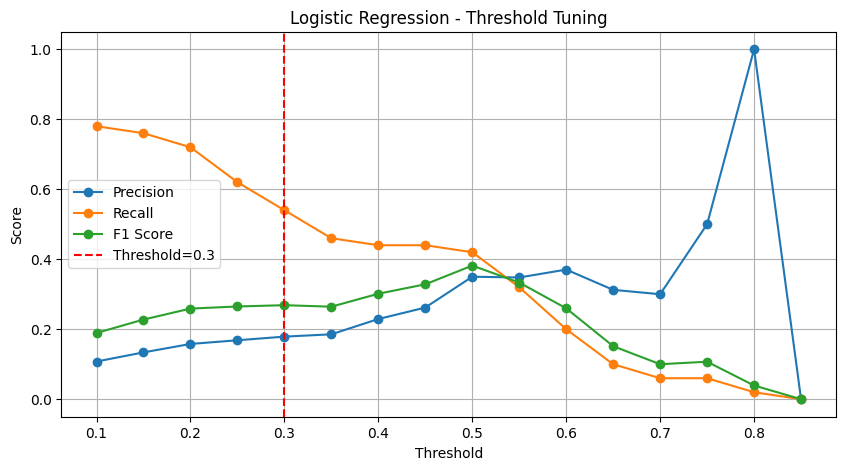

In [9]:
from sklearn.metrics import precision_recall_fscore_support
import matplotlib.pyplot as plt

# Use Logistic Regression - our best model so far
best_model = models["Logistic Regression"]
y_proba = best_model.predict_proba(X_test_scaled)[:,1]

thresholds = np.arange(0.1, 0.9, 0.05)
recalls, precisions, f1s = [], [], []

for thresh in thresholds:
    y_pred_thresh = (y_proba >= thresh).astype(int)
    p, r, f, _ = precision_recall_fscore_support(
        y_test, y_pred_thresh, average='binary', zero_division=0
    )
    precisions.append(p)
    recalls.append(r)
    f1s.append(f)

plt.figure(figsize=(10, 5))
plt.plot(thresholds, precisions, marker='o', label='Precision')
plt.plot(thresholds, recalls, marker='o', label='Recall')
plt.plot(thresholds, f1s, marker='o', label='F1 Score')
plt.axvline(x=0.3, color='red', linestyle='--', label='Threshold=0.3')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title('Logistic Regression - Threshold Tuning')
plt.legend()
plt.grid(True)
plt.show()

In [12]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    scale_pos_weight=len(y_train[y_train==0]) / len(y_train[y_train==1]),
    random_state=42,
    eval_metric='logloss'
)

xgb.fit(X_train_scaled, y_train_res)
y_pred_xgb = xgb.predict(X_test_scaled)
auc_xgb = roc_auc_score(y_test, xgb.predict_proba(X_test_scaled)[:,1])

print("XGBoost Results:")
print(classification_report(y_test, y_pred_xgb, target_names=['No Stroke','Stroke']))
print(f"ROC-AUC Score: {auc_xgb:.3f}")

XGBoost Results:
              precision    recall  f1-score   support

   No Stroke       0.98      0.74      0.85       972
      Stroke       0.12      0.68      0.20        50

    accuracy                           0.74      1022
   macro avg       0.55      0.71      0.52      1022
weighted avg       0.94      0.74      0.81      1022

ROC-AUC Score: 0.789


In [13]:
import joblib
import os

os.makedirs('../models', exist_ok=True)

# Save model and scaler - we need both!
joblib.dump(xgb, '../models/stroke_model.pkl')
joblib.dump(scaler, '../models/scaler.pkl')

print("✅ Model saved to models/stroke_model.pkl")
print("✅ Scaler saved to models/scaler.pkl")

✅ Model saved to models/stroke_model.pkl
✅ Scaler saved to models/scaler.pkl
